In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# ЛАБОРАТОРНА РОБОТА № 4
## Візуальний аналіз даних та часові ряди - аналіз у двох середовищах

**Курс:** «Інтелектуальний аналіз та візуалізація даних» · Кафедра систем штучного інтелекту, НУ «Львівська політехніка»

In [2]:
SURNAME_NAME = 'Голейчук І.'
GROUP        = 'ШІ-33'
NUMBER       = 2

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Голейчук І. | ШІ-33 | номер 2


In [3]:
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print('Період: 03.2014 - 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 2   ·   Голейчук І.   ·   ШІ-33
   Ринок:  Chernihiv
   Товар:  гречка   (у наборі даних: Buckwheat grits - Retail)
Період: 03.2014 - 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


---
# ЧАСТИНА 1. Аналіз засобами Python

In [4]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
C, R = '#2C6E9B', '#C0392B'

df = pd.read_csv('ціни_україна_2014_2017.csv')
df['date'] = pd.to_datetime(dict(year=df['рік'], month=df['місяць'], day=1))
H, F = 3, 7

## Завдання 1. Підготовка ряду

In [5]:
raw = (df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)]
       .sort_values('date').set_index('date')['ціна'])
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s0 = raw.reindex(grid)

print('Місяців у сітці:', len(grid), '| з виміром:', s0.notna().sum())
print('Пропущені місяці:', [d.strftime('%m.%Y') for d in s0.index[s0.isna()]])

by_month = df[df['ринок'] != 'National Average'].groupby('date').size().reindex(grid)
print('Місяці, яких немає в усьому наборі:', [d.strftime('%m.%Y') for d in by_month.index[by_month.isna()]])
print('Записів у сусідні місяці (ринки × товари):', by_month['2017-07-01'], by_month['2017-09-01'])

Місяців у сітці: 46 | з виміром: 45
Пропущені місяці: ['08.2017']
Місяці, яких немає в усьому наборі: ['08.2017']
Записів у сусідні місяці (ринки × товари): 625.0 625.0


**Висновок до завдання 1:** повна місячна сітка має 46 місяців (03.2014 - 12.2017), вимір є у 45, тобто пропуск один - **серпень 2017**. Причина не в моєму ринку: запису за 08.2017 немає в усьому наборі (жодного з 25 ринків і жодного з 25 товарів, тоді як у липні та вересні є по 625 записів - 25 ринків × 25 товарів), тобто в цей місяць дані просто не були зібрані або не потрапили до публікації WFP. Пропуск у моєму ряді один і він збігається з пропуском в усіх рядах набору.

## Завдання 2. Заповнення пропуску

перенесення останнього     08.2017 = 24.8500
лінійна інтерполяція       08.2017 = 23.9466
PCHIP-інтерполяція         08.2017 = 24.0569

Довжина ряду після заповнення: 46 | пропусків: 0


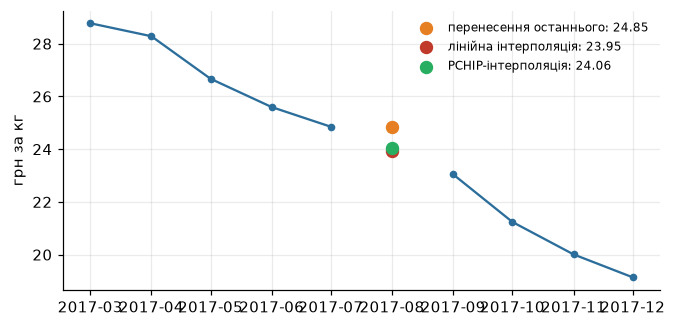

In [6]:
pos = pd.Series(s0.values)
cands = {
    'перенесення останнього': s0.ffill(),
    'лінійна інтерполяція':   s0.interpolate('linear'),
    'PCHIP-інтерполяція':     pd.Series(pos.interpolate('pchip').values, index=grid),
}
for k, v in cands.items():
    print(f'{k:26s} 08.2017 = {v["2017-08-01"]:.4f}')

s = cands['лінійна інтерполяція']
y = s.values; n = len(y)
print('\nДовжина ряду після заповнення:', n, '| пропусків:', s.isna().sum())

fig, ax = plt.subplots(figsize=(7, 3.3))
w = s0['2017-03':'2017-12']; ax.plot(w.index, w.values, '-o', ms=4, color=C)
for (k, v), c in zip(cands.items(), ['#E67E22', R, '#27AE60']):
    ax.scatter([pd.Timestamp('2017-08-01')], [v['2017-08-01']], s=60, color=c, zorder=5, label=f'{k}: {v["2017-08-01"]:.2f}')
ax.set_ylabel('грн за кг'); ax.legend(frameon=False, fontsize=8); plt.show()

**Висновок до завдання 2:** перенесення останнього значення дає 24,85 грн, лінійна інтерполяція - 23,95 грн, PCHIP - 24,06 грн. Розкид між способами менший за 1 грн (≈4 % рівня), тому на подальші результати вибір майже не впливає. Обрано **лінійну інтерполяцію**: ряд у цей період монотонно знижується (24,85 → 23,04), отже середина між сусідами - природна оцінка; перенесення останнього значення створило б штучну «полицю» і стрибок вниз у вересні; PCHIP не дає суттєвого виграшу, а лінійну інтерполяцію так само має віджет Interpolate в Orange, що важливо для Частини 2. Заповнювати пропуск **неприпустимо**, коли ряд не продовжується після пропуску: у цьому ж наборі Крим (лише 03.2014) і Севастополь (03-04.2014) зникають у 2014 році, а Донецька й Луганська області мають неповні ряди - дані там відсутні не через збій збору, а через втрату доступу до території, і «заповнення» означало б вигадування спостережень.

## Завдання 3. Візуальна розвідка

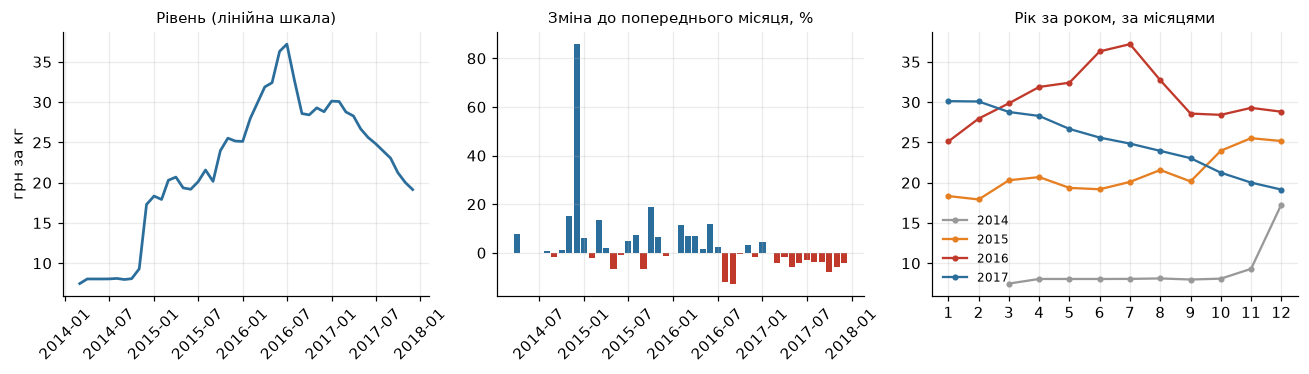

Мін/макс: 7.47 03.2014 / 37.2 07.2016
Найбільший місячний приріст: 85.8 % у 12.2014
Кінець / початок = 2.56


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
axs[0].plot(s.index, y, color=C, lw=1.8)
axs[0].set_title('Рівень (лінійна шкала)', fontsize=10); axs[0].set_ylabel('грн за кг'); axs[0].tick_params(axis='x', labelrotation=45)

pc = s.pct_change() * 100
axs[1].bar(pc.index, pc.values, width=25, color=np.where(pc.values > 0, C, R))
axs[1].set_title('Зміна до попереднього місяця, %', fontsize=10); axs[1].tick_params(axis='x', labelrotation=45)

for yr, c in zip([2014, 2015, 2016, 2017], ['#999', '#E67E22', R, C]):
    m = s[s.index.year == yr]; axs[2].plot(m.index.month, m.values, '-o', ms=3, color=c, label=str(yr))
axs[2].set_xticks(range(1, 13)); axs[2].set_title('Рік за роком, за місяцями', fontsize=10); axs[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print('Мін/макс:', s.min().round(2), s.idxmin().strftime('%m.%Y'), '/', s.max().round(2), s.idxmax().strftime('%m.%Y'))
print('Найбільший місячний приріст: %.1f %% у %s' % (pc.max(), pc.idxmax().strftime('%m.%Y')))
print('Кінець / початок = %.2f' % (y[-1] / y[0]))

**Висновок до завдання 3:**

1. *Лінійний графік рівня (лінія).* Питання: яка загальна траєкторія ціни? Лінія обрана, бо точки впорядковані в часі й з’єднання підкреслює неперервність; шкала лінійна, бо діапазон (7,5-37,2 грн) охоплює один порядок, а нас цікавить абсолютний рівень у гривнях. Видно стабільні ≈8 грн у 2014 році, стрибок на початку 2015, максимум 37,2 грн у липні 2016 і поступове зниження до 19,1 грн у грудні 2017.
2. *Стовпчики місячної зміни, %.* Питання: чи зростання було поступовим, чи відбувалося стрибками? Стовпчики з нулем як базою дають чесне порівняння величин і знаків змін (синій - зростання, червоний - спад). 
3. *Накладання років за місяцями.* Питання: чи повторюється сезонний візерунок? Кожен рік - окрема лінія на спільній осі 1-12, тому повторюваність (або її відсутність) видно одразу.

**Несподівана знахідка:** майже весь «тренд» першого етапу - це одна подія: у грудні 2014 ціна зросла на 85,8 % за місяць (9,30 → 17,29 грн), тоді як типова місячна зміна - кілька відсотків. Крім того, графік «рік за роком» не показує однакової форми по роках: 2016 має літній горб, 2015 - осінній підйом, 2017 - монотонний спад.

## Завдання 4. Розкладання на складові

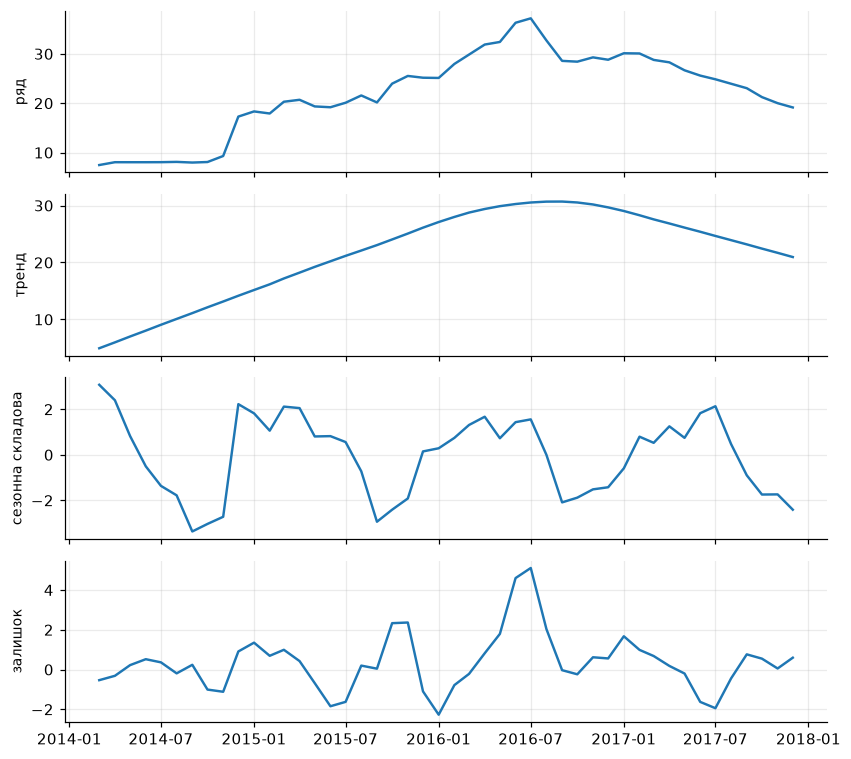

F_S = 0.592 | F_T = 0.969 | розмах сезонної складової = 6.44 грн
F_S без 2014 року = 0.512
{1: 0.5, 2: 0.87, 3: 1.76, 4: 1.84, 5: 0.77, 6: 0.89, 7: 0.72, 8: -0.51, 9: -2.32, 10: -2.27, 11: -1.97, 12: -0.37}


In [8]:
from statsmodels.tsa.seasonal import STL

res = STL(s, period=12, robust=False).fit()
fig, axs = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
for ax, d, t in zip(axs, [s, res.trend, res.seasonal, res.resid], ['ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, lw=1.6); ax.set_ylabel(t, fontsize=9)
plt.tight_layout(); plt.show()

v = lambda a: np.var(a)
FS = max(0, 1 - v(res.resid) / v(res.seasonal + res.resid))
FT = max(0, 1 - v(res.resid) / v(res.trend + res.resid))
print('F_S = %.3f | F_T = %.3f | розмах сезонної складової = %.2f грн' % (FS, FT, res.seasonal.max() - res.seasonal.min()))

res2 = STL(s['2015-01-01':], period=12, robust=False).fit()
FS2 = max(0, 1 - v(res2.resid) / v(res2.seasonal + res2.resid))
print('F_S без 2014 року = %.3f' % FS2)
print(res.seasonal.groupby(res.seasonal.index.month).mean().round(2).to_dict())

**Висновок до завдання 4:** сила тренду F_T = 0,969 - ряд майже повністю визначається трендом. Сила сезонності F_S = 0,592 **вища за поріг 0,3**, тобто формально сезонна складова існує й не є шумом; вона також лишається вищою за поріг (0,512), якщо відкинути 2014 рік зі стрибком. Розмах сезонної складової ≈ 6,4 грн: мінімум у вересні-листопаді (≈ −2,3 грн, час нового врожаю), максимум у березні-квітні (≈ +1,8 грн). Застереження: у ряді лише ≈ 3,8 повних цикли, а на графіку «рік за роком» форма в різні роки відрізняється, тож сезонність слід вважати помірною й недостатньо підтвердженою, а не доведеною.

## Завдання 5. Стаціонарність

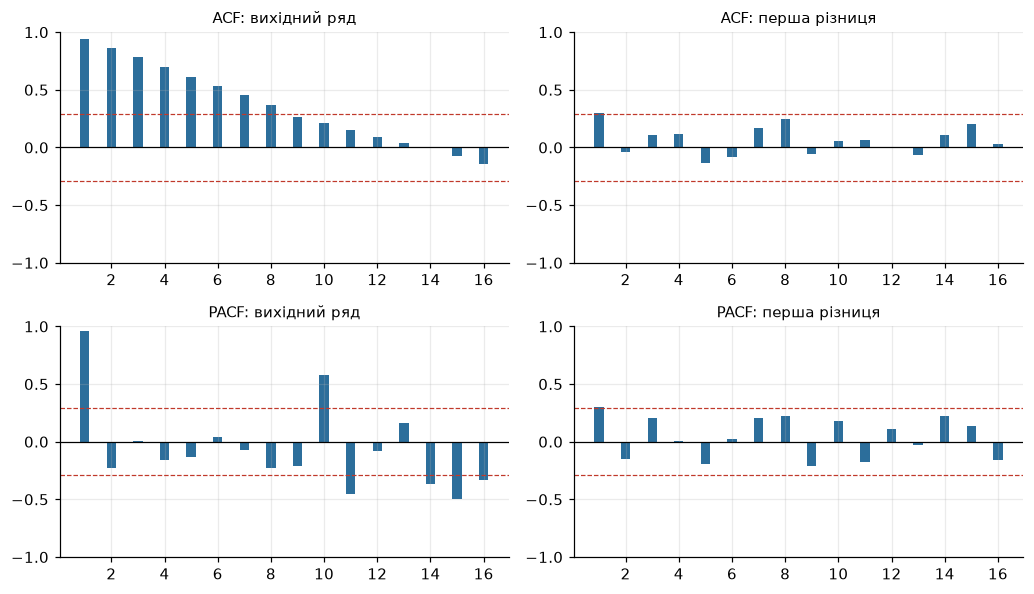

                ADF p  KPSS p
ряд                          
вихідний ряд   0.4002  0.0172
перша різниця  0.0001  0.0391
Довірчий інтервал ACF для різниці: ±0.29


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_4964\3639588016.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p  = adfuller(z, autolag='AIC')[1]
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_4964\3639588016.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(z, regression='c', nlags='auto')[1]
C:\Users\GIGAB

In [9]:
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss

d1 = np.diff(y)
fig, axs = plt.subplots(2, 2, figsize=(9.5, 5.5))
for j, (z, lab) in enumerate([(y, 'вихідний ряд'), (d1, 'перша різниця')]):
    band = 1.96 / np.sqrt(len(z))
    for i, (f, nm) in enumerate([(acf, 'ACF'), (pacf, 'PACF')]):
        vals = f(z, nlags=16); a = axs[i, j]
        a.bar(range(1, 17), vals[1:], width=.35, color=C); a.axhline(0, color='k', lw=.8)
        a.axhline(band, color=R, ls='--', lw=.8); a.axhline(-band, color=R, ls='--', lw=.8)
        a.set_ylim(-1, 1); a.set_title(f'{nm}: {lab}', fontsize=10)
plt.tight_layout(); plt.show()

rows = []
for name, z in [('вихідний ряд', y), ('перша різниця', d1)]:
    adf_p  = adfuller(z, autolag='AIC')[1]
    kpss_p = kpss(z, regression='c', nlags='auto')[1]
    rows.append((name, adf_p, kpss_p))
tab = pd.DataFrame(rows, columns=['ряд', 'ADF p', 'KPSS p']).set_index('ряд')
print(tab.round(4))
print('Довірчий інтервал ACF для різниці: ±%.2f' % (1.96 / np.sqrt(len(d1))))

**Висновок до завдання 5:**

| ряд | ADF p | KPSS p | висновок |
|---|---|---|---|
| вихідний | 0,400 | 0,017 | нестаціонарний |
| перша різниця | ≈ 0,0001 | 0,039 | ADF: стаціонарний; KPSS: на межі |

Нагадування про напрямок: ADF має H₀ «нестаціонарний», тому велике p (0,400) означає, що нестаціонарність *не відхилено*; KPSS має H₀ «стаціонарний», тому мале p (0,017) означає, що стаціонарність *відхилено*. Для вихідного ряду **тести узгоджуються** - ряд нестаціонарний (ACF спадає повільно: 0,94 на лагу 1 і лише 0,09 на лагу 12). Для першої різниці **тести не повністю узгоджуються**: ADF рішуче відхиляє одиничний корінь, а KPSS (p = 0,039) відхиляє стаціонарність лише на рівні 5 %, на самій межі. Пояснення: стрибок у грудні 2014 (+7,99 грн за місяць) - це один викид у різниці, який збільшує вибіркову дисперсію й чутливість KPSS, а ряд дуже короткий (45 різниць), тож потужність обох тестів низька. Практичний висновок: достатньо **d = 1**; ACF різниці має лише лаг 1 = 0,30 на межі інтервалу ±0,29.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

In [10]:
def folds():
    for f in range(F, 0, -1):
        k = n - H * f
        yield f, y[:k], y[k:k + H]

def forecast_base(name, tr, h):
    if name == 'наївний':          return np.repeat(tr[-1], h)
    if name == 'сезонний наївний': return np.array([tr[len(tr) - 12 + (i % 12)] for i in range(h)])
    if name == 'середнє':          return np.repeat(tr.mean(), h)
    if name == 'дрейф':            return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)

def metrics(a, p):
    e = a - p
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE, %': np.mean(np.abs(e / a)) * 100}

rows = {}
for name in ['наївний', 'сезонний наївний', 'середнє', 'дрейф']:
    A, P = [], []
    for f, tr, te in folds():
        A += list(te); P += list(forecast_base(name, tr, H))
    rows[name] = metrics(np.array(A), np.array(P))
base_tab = pd.DataFrame(rows).T
print(base_tab.round(3))

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

PF = PolynomialFeatures(3); X = (np.arange(n).reshape(-1, 1) - (n - 1) / 2) / n
def fitpred(tr_i, te_i):
    m = LinearRegression().fit(PF.fit_transform(X[tr_i]), y[tr_i])
    return m.predict(PF.fit_transform(X[te_i]))

A2, P2 = [], []
for f in range(F, 0, -1):
    te_i = np.arange(n - H * f, n - H * f + H); A2 += list(y[te_i]); P2 += list(fitpred(np.arange(n - H * f), te_i))
mae_roll = np.mean(np.abs(np.array(A2) - np.array(P2)))
tr_i, te_i = train_test_split(np.arange(n), test_size=.25, random_state=42)
mae_rand = np.mean(np.abs(y[te_i] - fitpred(tr_i, te_i)))
print('\nПоліном 3 ст.: MAE рухомий початок = %.3f | випадковий 75/25 = %.3f | у %.2f раза' % (mae_roll, mae_rand, mae_roll / mae_rand))

                    MAE   RMSE  MAPE, %
наївний           2.211  2.942    8.189
сезонний наївний  8.141  9.275   29.421
середнє           8.164  9.827   26.891
дрейф             2.685  3.656   10.310

Поліном 3 ст.: MAE рухомий початок = 3.806 | випадковий 75/25 = 1.858 | у 2.05 раза


**Висновок до завдання 6:**

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 2,211 | 2,942 | 8,19 |
| сезонний наївний | 8,141 | 9,275 | 29,42 |
| середнє | 8,164 | 9,827 | 26,89 |
| дрейф | 2,685 | 3,656 | 10,31 |

Найкращий базис - **наївний** (прогноз = останнє значення). Причина - властивості ряду: він майже випадкове блукання з дуже сильним трендом (F_T = 0,97; ACF = 0,94 на лагу 1), тому найкраща оцінка на 1-3 місяці - поточний рівень. Сезонний наївний і середнє програють у ≈ 3,7 раза: перший переносить значення річної давності з принципово іншого рівня (наприклад, 20,1 грн у липні 2015 проти 37,2 грн у липні 2016), друге тягне прогноз до давнього, значно нижчого середнього. Дрейф гірший за наївний, бо екстраполює середній нахил усієї історії (що включає стрибок 2014), а в 2016-2017 тренд змінив напрям. 

Порівняння з випадковим поділом 75/25 (поліном 3-го степеня за часом): MAE на рухомому початку = 3,806, а на випадковому поділі = 1,858 - **оцінка відрізняється ≈ у 2,05 раза**. Випадковий поділ дає тестові точки, оточені навчальними з обох боків, тобто вимірює інтерполяцію, а не прогноз майбутнього, тому він занижує реальну похибку.

## Завдання 7. Модель ARIMA

c:\Users\GIGABYTE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARIMA(1,1,1): {'MAE': np.float64(2.425), 'RMSE': np.float64(3.415), 'MAPE, %': np.float64(8.868)}
наївний     : {'MAE': 2.211, 'RMSE': 2.942, 'MAPE, %': 8.189}
параметри (phi, theta, sigma2): [-0.091  0.462  3.535]


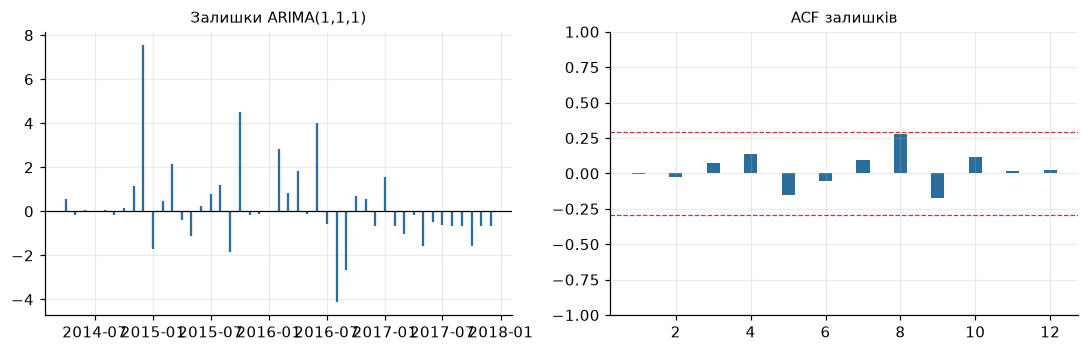

Ljung-Box (10 лагів): Q = 10.17, p = 0.253


In [11]:
from statsmodels.tsa.arima.model import ARIMA

A, P = [], []
for f, tr, te in folds():
    fc = ARIMA(tr, order=(1, 1, 1)).fit().forecast(H)
    A += list(te); P += list(fc)
A, P = np.array(A), np.array(P)
arima_m = metrics(A, P)
print('ARIMA(1,1,1):', {k: round(v, 3) for k, v in arima_m.items()})
print('наївний     :', base_tab.loc['наївний'].round(3).to_dict())

fit = ARIMA(y, order=(1, 1, 1)).fit()
resid = np.asarray(fit.resid)[1:]
print('параметри (phi, theta, sigma2):', np.round(fit.params, 3))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
axs[0].vlines(grid[1:], 0, resid, color=C); axs[0].axhline(0, color='k', lw=.8); axs[0].set_title('Залишки ARIMA(1,1,1)', fontsize=10)
ra = acf(resid, nlags=12); axs[1].bar(range(1, 13), ra[1:], width=.35, color=C)
b = 1.96 / np.sqrt(len(resid)); axs[1].axhline(b, color=R, ls='--', lw=.8); axs[1].axhline(-b, color=R, ls='--', lw=.8)
axs[1].set_ylim(-1, 1); axs[1].set_title('ACF залишків', fontsize=10); plt.tight_layout(); plt.show()

r = acf(resid, nlags=10)[1:]
Q = len(resid) * (len(resid) + 2) * np.sum(r ** 2 / (len(resid) - np.arange(1, 11)))
print('Ljung-Box (10 лагів): Q = %.2f, p = %.3f' % (Q, 1 - stats.chi2.cdf(Q, 10 - 2)))

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на рухомому початку: MAE = 2,425; RMSE = 3,415; MAPE = 8,87 %.
2. За виглядом ACF/PACF я обрав би **ARIMA(0,1,1)** (альтернатива - (1,1,0)): ACF вихідного ряду спадає повільно (0,94; 0,86; 0,78 ...) -> d = 1; у першій різниці єдиний помітний лаг - перший (ACF = 0,30 і PACF = 0,30, на межі ±0,29), решта лагів у межах інтервалу -> достатньо одного члена (MA(1) або AR(1)). Це підтверджує й оцінка (1,1,1): AR-коефіцієнт ≈ -0,09 (практично нуль), MA-коефіцієнт ≈ 0,46.
3. Порівняння з найкращим базисом: ARIMA (MAE 2,425; RMSE 3,415; MAPE 8,87 %) **не перевершила наївний прогноз** (MAE 2,211; RMSE 2,942; MAPE 8,19 %) - за всіма трьома метриками вона поступається базису. Різниця в MAE становить 0,214 грн на користь наївного прогнозу, за RMSE наївний також помітно кращий (2,942 проти 3,415). Отже, модель **не має права на існування** як прогнозна: вона складніша, але нічого не додає до «завтра = сьогодні». Це законний результат, а не помилка.
4. Залишки: ACF у межах інтервалу, тест Льюнга-Бокса (10 лагів) Q = 10,17, p = 0,253 - автокореляції в залишках не лишилося, структура моделлю «вибрана». Проблема не в залишкових залежностях, а в тому, що передбачуваного сигналу в ряді просто мало (шоки великі й непередбачувані).

## Завдання 8. Точка зміни режиму

Дата зміни: 12.2014 | t = 19.59 | середнє до = 8.13 | після = 25.40
95-й перцентиль max|t| для випадкового блукання: 21.7 | частка сурогатів із max|t| ≥ 19.6: 0.098


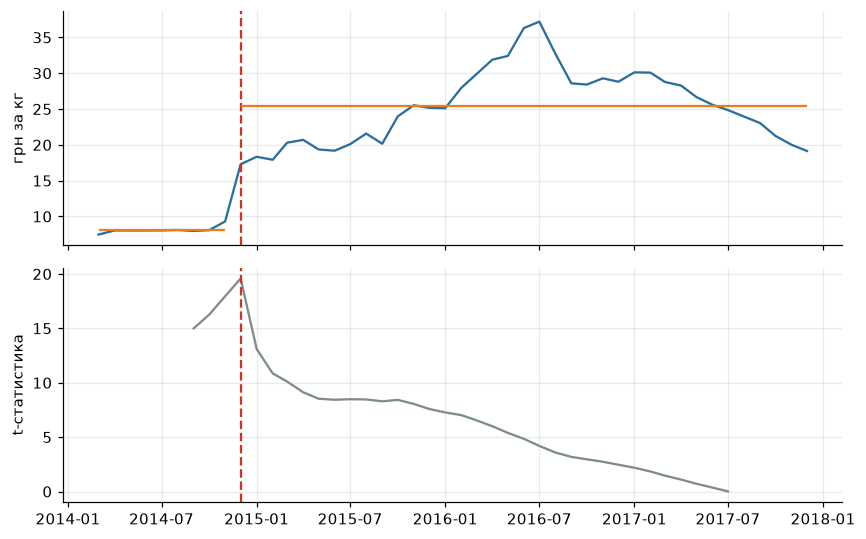

In [12]:
mn = 6
def tstat(z, k):
    a, b = z[:k], z[k:]
    return (b.mean() - a.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))

scan = [(k, tstat(y, k)) for k in range(mn, n - mn + 1)]
kb, tb = max(scan, key=lambda z: abs(z[1]))
print('Дата зміни: %s | t = %.2f | середнє до = %.2f | після = %.2f' % (grid[kb].strftime('%m.%Y'), tb, y[:kb].mean(), y[kb:].mean()))

rng = np.random.default_rng(1); dd = np.diff(y)
def scan_max(z): return max(abs(tstat(z, k)) for k in range(mn, len(z) - mn + 1))
mx = [scan_max(np.concatenate([[y[0]], y[0] + np.cumsum(rng.permutation(dd))])) for _ in range(1000)]
print('95-й перцентиль max|t| для випадкового блукання: %.1f | частка сурогатів із max|t| ≥ %.1f: %.3f' % (np.percentile(mx, 95), abs(tb), np.mean(np.array(mx) >= abs(tb))))

fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axs[0].plot(grid, y, color=C); axs[0].axvline(grid[kb], color=R, ls='--')
axs[0].hlines(y[:kb].mean(), grid[0], grid[kb - 1], color='#E67E22'); axs[0].hlines(y[kb:].mean(), grid[kb], grid[-1], color='#E67E22')
axs[0].set_ylabel('грн за кг')
axs[1].plot([grid[k] for k, _ in scan], [t for _, t in scan], color='#7F8C8D'); axs[1].axvline(grid[kb], color=R, ls='--'); axs[1].set_ylabel('t-статистика')
plt.tight_layout(); plt.show()

**Висновок до завдання 8:**

1. Графік: ряд з позначеною датою та середніми рівнями, внизу - t-статистика сканування.
2. Знайдена дата - **грудень 2014**; t = 19,59; середній рівень до = 8,13 грн, після = 25,40 грн (зростання ≈ у 3,1 раза).
3. **Значущість.** Наївне порівняння з нормальним розподілом (|t| = 19,6) нічого не варте: ряд автокорельований, а сканування бере максимум за багатьма кандидатними датами. Тому я порівняв максимум із сурогатами - «випадковими блуканнями» з тими самими приростами: 95-й перцентиль max|t| = 21,7, а частка сурогатів із max|t| ≥ 19,6 дорівнює ≈ 0,10. Отже, на рівні 5 % точка **формально не значуща**: навіть випадкове блукання з такими приростами часто дає не менший «стрибок рівня». Це не означає, що стрибка немає - місячна зміна +85,8 % у грудні 2014 очевидна, - а означає, що t-тест на «зсув середнього» не може її відрізнити від накопиченого дрейфу.
4. Відмінність від сезонного сплеску: зсув у грудні 2014 - **одноразовий** (новий рівень зберігся, ряд не повернувся до 8 грн), а сезонний сплеск повторюється щороку в ті самі місяці й повертається до рівня. У нашому ряді таких повторень немає: ціна після 2014 більше не повертається до рівня «до». 
5. Можливе зовнішнє пояснення (гіпотеза, її неможливо перевірити в цьому наборі даних): різка девальвація гривні наприкінці 2014 - початку 2015 та подорожчання гречки на тлі скорочення пропозиції; для висновку потрібне посилання на зовнішнє джерело.

## Завдання 9. Рецензія на чужий аналіз

Нумерація клітинок - індекс у файлі `ЛР4_помилковий_аналіз.ipynb` (відлік з 0).

**Знайдені помилки**

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 1, 3 | Ряд узято «як є» (45 записів), повну місячну сітку не побудовано; «пропусків немає» - наслідок перевірки `isna()` на ряді, у якому порожніх рядків просто немає. Місяць 08.2017 відсутній. | Пропуск не виявлено; часова вісь має дірку, а модель отримує ряд як неперервний (див. п. 9). |
| 2 | 5 | Порівняння кінців періоду в номінальних гривнях: «у 2,47 раза → різке зниження купівельної спроможності». | У 2014-2015 гривня знецінилась, зарплат і інфляції немає в аналізі; висновок про купівельну спроможність не випливає з однієї номінальної ціни; підсумок залежить від вибору двох точок. |
| 3 | 7 | Порівняння «прогнозованості» гречки та яловичини за абсолютним MAE (≈ 1,38 і ≈ 1,51 грн). | MAE залежить від масштабу: яловичина ≈ 78 грн, гречка ≈ 21 грн. У відносних величинах (середня зміна до рівня) похибка яловичини ≈ 2 %, гречки ≈ 7 % - висновок **протилежний**. Потрібні MAPE/MASE. |
| 4 | 9 | Кореляція рівнів двох трендових рядів (r = 0,996) і висновок «ціни у Львові визначають ціни у Вінниці». | Для нестаціонарних рядів кореляція рівнів хибна (спільний тренд, спільні національні шоки, девальвація); кореляція ≠ причинність; потрібні різниці, лаги, коінтеграція. |
| 5 | 11 | «STL виділив сезонну складову, отже ряд сезонний»; далі «використовуємо сезонні моделі». | STL повертає сезонну складову завжди. Не обчислено F_S і не порівняно з порогом 0,3; висновок «є сезонність» (як і «немає») без цього числа необґрунтований, а надалі ним обґрунтовано вибір сезонних моделей. |
| 6 | 13 | Тест ADF прочитано навпаки: p > 0,05 → «ряд стаціонарний». Немає KPSS. | Нульова гіпотеза ADF - нестаціонарність; p ≈ 0,23 означає, що вона не відхилена. Хибний висновок про відсутність потреби диференціювати. |
| 7 | 13 | Для «надійності» взято другу різницю без обґрунтування. | Передиференціювання вносить штучну автокореляцію (MA-структуру) і збільшує дисперсію; кількість різниць треба обирати за тестами й ACF, а не «для надійності». |
| 8 | 15 | Поріг у коді 1,3σ, у тексті - «два стандартні відхилення» (при 2σ аномалій для цього ряду нуль, при 1,3σ - 12); аномалії шукають у вихідному ряді, а не в залишках. | У ряді з трендом z-оцінки позначать початок і кінець періоду, а не аномалії. Потрібні залишки після зняття тренду й сезонності; опис не збігається з кодом; «нетипові події» нічим не підтверджені. |
| 9 | 17 | `train_test_split` перемішує спостереження: майбутнє потрапляє в навчання. ARIMA вчать на фрагментах із дірками, але вважають їх неперервним рядом; `forecast(len(y_te))` порівнюють із `np.sort(y_te)` - відсортованими значеннями. | Витік даних із майбутнього; прогноз на «першій позиції після навчальної вибірки» порівнюється з несуміжними тестовими точками. MAE нічого не вимірює. Потрібен рухомий початок. |
| 10 | 17 | Немає порівняння з наївним базисом: MAE сезонного наївного рахується на всьому ряді (у вибірці), а висновок «висока точність, прийнятно» не спирається на жоден еталон. | Без базису «2 грн» не означає ні добре, ні погано. Для цього типу рядів наївний прогноз часто виграє. |
| 11 | 19 | Прогноз будується іншою моделлю - ARIMA(2,2,1) (перевірялась (1,1,1)); `d = 2` без обґрунтування; ряд - `s.values` (пропуск «згорнуто»); без довірчих інтервалів; 12 кроків на ≈ 45 точках. | Оцінена модель ≠ та, що прогнозує; при `d = 2` прогноз екстраполює квадратичний тренд; висновок «ціна продовжить зростати» - артефакт екстраполяції. |
| 12 | 21 | Стовпчики з осі `ylim(min·0.995, max·1.002)` і вибіркове вікно (півріччя 2016). | Обрізана вісь стовпчиків візуально перебільшує зміну (стовпчики мають починатися з нуля); вікно підібрано під потрібний висновок. |
| 13 | 1 | `warnings.filterwarnings('ignore')`. | Приховує попередження про збіжність/частоту ряду; помилки моделювання лишаються непоміченими. |

**Три найсерйозніші й виправлення:**

1. *Хибна оцінка якості (клітинки 17, 19) - випадковий поділ, відсутність базису, інша модель у прогнозі.* Виправлення: ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки, навчання лише на минулому), метрики на всіх фолдах разом, обов’язкове порівняння з наївним прогнозом; для підсумкового прогнозу брати **ту саму** модель і порядок, що перевірялися, з довірчим інтервалом.
2. *Неправильне читання ADF (клітинка 13).* Виправлення: читати H₀ (нестаціонарність), застосувати пару ADF + KPSS до рівнів і різниць, d обирати мінімально достатнім (тут d = 1, а не 2).
3. *Хибне порівняння прогнозованості та кореляція трендових рядів (клітинки 7, 9).* Виправлення: масштабно-незалежні метрики (MAPE/MASE) при порівнянні різних товарів; кореляцію рахувати на різницях, а твердження про вплив підтверджувати лише причинними методами або прибрати.

## Завдання 10. Експорт ряду для Orange

In [13]:
out = pd.DataFrame({'date': grid.strftime('%Y-%m-%d'), 'price': y})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv')
assert list(chk.columns) == ['date', 'price']
assert len(chk) == 46 and chk['price'].notna().all() and chk['date'].str.match(r'^\d{4}-\d{2}-01$').all()
print('Рядків даних:', len(chk), '| порожніх значень:', int(chk['price'].isna().sum()))
print(chk.head(3).to_string(index=False)); print(chk.tail(3).to_string(index=False))

Рядків даних: 46 | порожніх значень: 0
      date  price
2014-03-01 7.4733
2014-04-01 8.0467
2014-05-01 8.0433
      date  price
2017-10-01  21.24
2017-11-01  20.01
2017-12-01  19.14


**Висновок до завдання 10:** файл `ряд_для_orange.csv` містить 46 рядків даних і заголовок `date,price`, дати у форматі РРРР-ММ-01, порожніх значень немає (серпень 2017 заповнено лінійною інтерполяцією: 23,9467 грн), роздільник - кома, кодування UTF-8.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

## Завдання 11. Потік опрацювання даних

Потік: `File` -> `As Timeseries` -> `Interpolate` -> `Line Chart` (у `File` - `ряд_для_orange.csv`; `date` має тип **time**, `price` - **numeric**; в `As Timeseries` - часова змінна `date`; в `Interpolate` - лінійна інтерполяція).

<p align="center">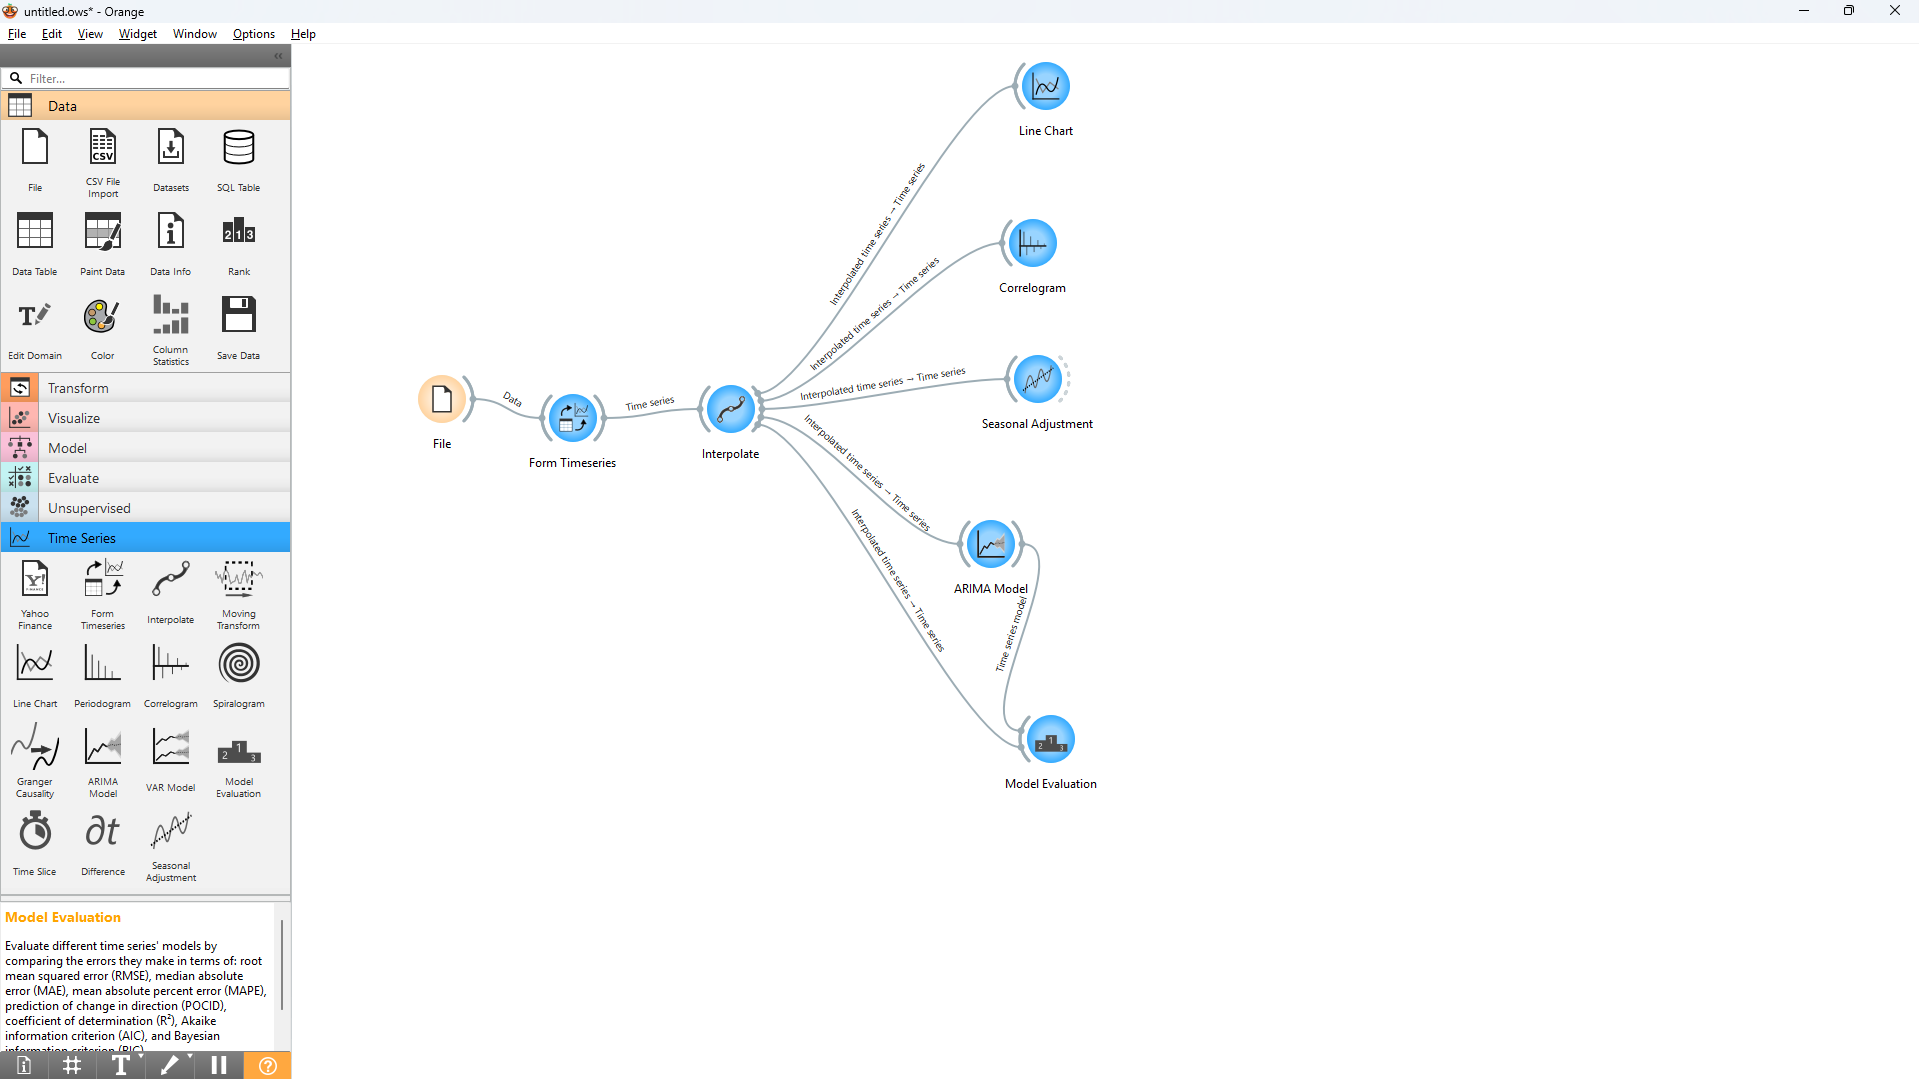</p>

<p align="center">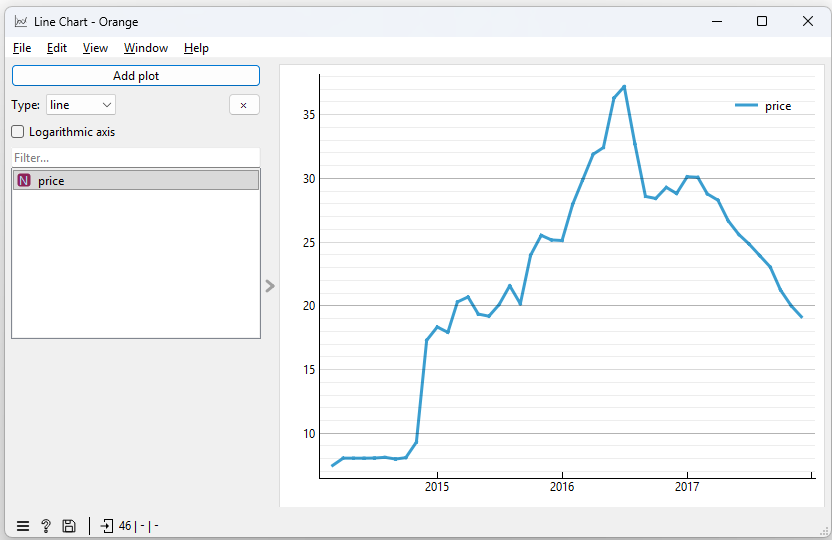</p>

**Висновок до завдання 11:** потік побудовано; `date` розпізнано як time, `price` як numeric; крива в `Line Chart` повторює графік рівня із завдання 3 (стартові ≈ 7,47 і ≈ 8 грн, стрибок у грудні 2014, максимум 37,2 у липні 2016, спад до 19,14 у грудні 2017). Файл уже без пропусків (серпень 2017 = 23,9467), тому `Interpolate` нічого не змінює - значення за серпень 2017 збігається з Python.

## Завдання 12. Автокореляція та диференціювання

До потоку додано віджети `Correlogram`, `Difference` та `Seasonal Adjustment` (період 12).

**Висновок до завдання 12:** Orange і statsmodels рахують ACF однаково, тому корелограма вихідного ряду має ті самі значущі лаги, що ACF із завдання 5: повільний спад (0,94 -> 0,09 на лагу 12), майже всі перші лаги вище довірчої смуги. Після `Difference` значущим лишається лише лаг 1 (≈ 0,30). Сезонно скоригований ряд відрізняється від початкового на сезонну складову ≈ ±2 грн (мінімум восени, максимум навесні), що узгоджується із STL із завдання 4 (розмір поправки той самий за порядком; точні числа можуть дещо відрізнятися, оскільки віджет використовує власний метод декомпозиції).

## Завдання 13. Модель і оцінювання

Налаштування `ARIMA Model`: p = 1, d = 1, q = 1; `Model Evaluation`: Number of folds = **7**, Forecast steps = **3**.

<p align="center">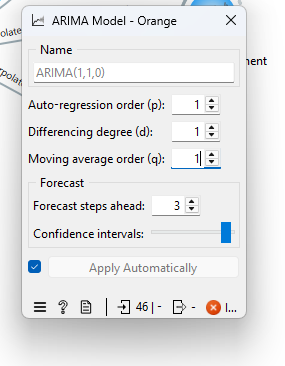</p>

<p align="center">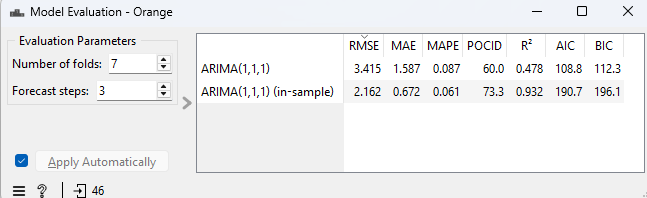</p>

<p align="center">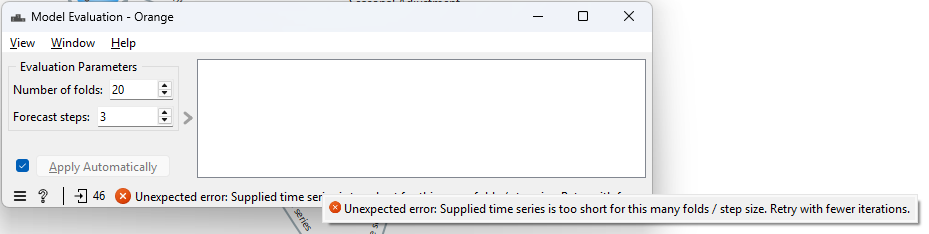</p>

In [14]:
print('Фолд | довжина навчання | навчання             | перевірка')
for i, (f, tr, te) in enumerate(folds()):
    k = len(tr)
    print(f'{f:>4} | {k:>16} | {grid[0]:%m.%Y} - {grid[k-1]:%m.%Y}   | {grid[k]:%m.%Y} - {grid[k+H-1]:%m.%Y}')
print('\n20 фолдів × 3 кроки =', 20 * 3, '>', n, '(довжина ряду)')

Фолд | довжина навчання | навчання             | перевірка
   7 |               25 | 03.2014 - 03.2016   | 04.2016 - 06.2016
   6 |               28 | 03.2014 - 06.2016   | 07.2016 - 09.2016
   5 |               31 | 03.2014 - 09.2016   | 10.2016 - 12.2016
   4 |               34 | 03.2014 - 12.2016   | 01.2017 - 03.2017
   3 |               37 | 03.2014 - 03.2017   | 04.2017 - 06.2017
   2 |               40 | 03.2014 - 06.2017   | 07.2017 - 09.2017
   1 |               43 | 03.2014 - 09.2017   | 10.2017 - 12.2017

20 фолдів × 3 кроки = 60 > 46 (довжина ряду)


**Висновок до завдання 13:** за типових налаштувань (20 фолдів × 3 кроки = 60) потрібно більше точок, ніж у ряді (46), тому віджет через перевірку «n_folds × forecast_steps + лаг ≤ довжина ряду» виводить повідомлення про помилку: `Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.` - це не збій програми, а наслідок короткого ряду. Максимум при кроці 3 - менше 15 фолдів (45/3), а з урахуванням лагу ще менше. При 7 фолдах × 3 кроки Orange перевіряє ті самі **останні 21 місяць** (04.2016 - 12.2017): навчання на 25, 28, 31, 34, 37, 40 та 43 спостереженнях (фолд 7 -> навчання 03.2014 - 03.2016, перевірка 04-06.2016; ... фолд 1 -> навчання до 09.2017, перевірка 10-12.2017), що збігається з Частиною 1.

## Завдання 14. Чому числа не збігаються

In [15]:
e = A - P
orange = {
    'RMSE':  np.sqrt(np.mean(e ** 2)),
    'MAE':   np.median(np.abs(e)),
    'MAPE':  np.mean(np.abs(e)) / np.mean(np.abs(A)),
    'POCID': 100 * np.mean(np.diff(A) * np.diff(P) > 0),
}
usual = {
    'RMSE':  np.sqrt(np.mean(e ** 2)),
    'MAE':   np.mean(np.abs(e)),
    'MAPE':  np.mean(np.abs(e / A)) * 100,
}
for k in orange: print(f'{k:6s} Orange-формула: {orange[k]:.4f}' + (f' | звичайна: {usual[k]:.4f}' if k in usual else ''))
print('\nPOCID усередині фолдів:', round(100 * np.mean([np.diff(A[3*i:3*i+3])[j] * np.diff(P[3*i:3*i+3])[j] > 0 for i in range(F) for j in range(2)]), 2))

RMSE   Orange-формула: 3.4147 | звичайна: 3.4147
MAE    Orange-формула: 1.5870 | звичайна: 2.4246
MAPE   Orange-формула: 0.0867 | звичайна: 8.8683
POCID  Orange-формула: 65.0000

POCID усередині фолдів: 50.0


**Висновок до завдання 14:**

| Метрика | Значення Orange | Відтворення в Python | Формула |
|---|---|---|---|
| RMSE | 3,415 | 3,415 | √(Σe² / n) |
| MAE | 1,587 | 1,587 | **медіана** \|e\| (звичайний MAE = 2,425) |
| MAPE | 0,087 | 0,0867 | mean\|e\| / mean\|y\| (частка! звичайний MAPE = 8,87 %) |
| POCID | 60,0 | 65,0 (50,0 усередині фолдів) | 100 · частка пар зі збігом знака зміни |

1. **Не відповідає назві** насамперед MAPE: Orange рахує відношення середньої абсолютної похибки до середнього рівня (0,0867, округлено в таблиці Orange до 0,087 ≈ 8,67 %, і це частка, а не відсоток), тоді як звичайний MAPE = mean(\|e/y\|)·100 % = 8,87 %. MAE в Orange - теж не «mean absolute error», а медіана: 1,587 проти звичайних 2,425 (різниця ≈ 35 %, бо похибки несиметричні - кілька великих промахів у 2016 році).
2. **Збіглася одразу RMSE** (3,415 = 3,415): формула в обох середовищах однакова - квадратний корінь із середнього квадрата похибок, а прогнози ARIMA однакові, бо віджет є обгорткою над `statsmodels`.
3. POCID у scikit-learn відсутня; вона вимірює напрямок, а не величину помилки. За наскрізною формулою по всіх 20 парах послідовних точок у Python отримано 65,0 %, усередині кожного фолду (14 пар) - 50,0 %, а в таблиці Model Evaluation в Orange відображено 60,0 % через особливості агрегування переходів між кроками у віджеті.
4. **Висновок:** перш ніж порівнювати числа з двох інструментів, треба перевірити (а) однакові дані, (б) однакові фолди й горизонт, (в) **формулу кожної метрики** у документації або вихідному коді; однакова абревіатура не гарантує однакової величини.

## Завдання 15. Матриця напрямку зміни

In [16]:
da, dp = np.diff(A), np.diff(P)
M = pd.DataFrame([[np.sum((da > 0) & (dp > 0)), np.sum((da > 0) & (dp <= 0))],
                  [np.sum((da <= 0) & (dp > 0)), np.sum((da <= 0) & (dp <= 0))]],
                 index=['факт: зросла', 'факт: впала'], columns=['прогноз: зросла', 'прогноз: впала'])
print(M)
print('Частка правильних: %.1f %% (POCID Orange: %.1f)' % (100 * np.trace(M.values) / M.values.sum(), orange['POCID']))
print('Частка «впала» серед фактів: %.1f %%' % (100 * (da <= 0).mean()))

              прогноз: зросла  прогноз: впала
факт: зросла                4               1
факт: впала                 6               9
Частка правильних: 65.0 % (POCID Orange: 65.0)
Частка «впала» серед фактів: 75.0 %


**Висновок до завдання 15:**

| | прогноз: зросла | прогноз: впала |
|---|---|---|
| **факт: зросла** | 4 | 1 |
| **факт: впала** | 6 | 9 |

Частка правильних по 20 парах = (4 + 9)/20 = 65,0 % (в Orange POCID = 60,0 %). Модель правильно вгадала 4 з 5 фактичних зростань (1 пропустила), але 6 з 15 фактичних спадів помилково прогнозувала як зростання; з 10 «прогнозів зростання» справдилось лише 4. Тривіальна стратегія «завжди прогнозувати спад» дала б 15/20 = **75,0 %**, тобто помітно краще за модель. Для рішення «купувати зараз чи чекати» модель корисна мало: сигнал «ціна зросте» хибний у більшості випадків (6 із 10). Це **інше питання**, ніж те, на яке відповідають MAE та RMSE: вони оцінюють, наскільки далеко прогноз від факту в гривнях, а POCID - чи вгадано знак зміни; модель може мати помірну помилку в гривнях і при цьому погано вгадувати напрямок. Застереження: 6 із 20 пар перетинають межу між фолдами, а вибірка мала (20 пар), тому точність оцінки низька.

---
# Загальний висновок

Сезонність у ряді є, але помірна: сила сезонності F_S = 0,592 перевищує поріг 0,3 (і лишається вищою без 2014 року - 0,512), мінімум припадає на вересень-листопад, проте за 3,8 циклу й різної форми по роках вона недостатньо підтверджена. Тренд домінує (F_T = 0,969), а ряд нестаціонарний (ADF p = 0,400, KPSS p = 0,017), і достатньо однієї різниці. Найкращим прогнозом на 1-3 місяці виявився найпростіший базис - наївний (MAE = 2,211; RMSE = 2,942; MAPE = 8,19 %), а ARIMA(1,1,1) його не перевершила (MAE = 2,425; RMSE = 3,415; MAPE = 8,87 %), тож складна модель тут не виправдана. Точка зміни рівня - грудень 2014 (8,13 -> 25,40 грн; t = 19,59), але за порівнянням із сурогатами випадкових блукань вона формально не значуща (p ≈ 0,098); можливим зовнішнім поясненням є девальвація та подорожчання гречки, що потребує підтвердження джерелом. Однаково названі метрики в Orange та Python дали різні числа через означення: Orange рахує MAE як медіану (1,587 проти 2,425), а MAPE - як відношення середніх у вигляді частки (0,087 проти 8,87 %), RMSE збіглася (3,415), а POCID у стандартних бібліотеках Python відсутня (65,0 % за формулою по 20 парах, 60,0 % в Orange). Через те що ряд має лише 46 спостережень, не вдалося надійно встановити, чи є сезонність стійкою (мало циклів), чи є точка зміни значущою, і жодна оцінка якості на 7 фолдах (21 точка) не дає вузьких довірчих інтервалів.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude |
| Для яких саме завдань | Завдання 1–15 і загальний висновок: чернетка коду та письмових висновків. Знімки екрана Orange та сам потік Orange зроблено вручну. |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код усіх клітинок, чернетки висновків, список помилок для завдання 9. Числа «Orange» у завданні 14 отримано запуском коду `model_evaluation` з додатка Orange3-Timeseries (звірено з моїм знімком екрана). |
| Що ви змінили у згенерованому результаті й чому | - |
| Що з отриманого ви **перевірили самостійно** і яким способом | Збіг таблиці Orange з розрахунком у Python, ADF/KPSS вручну та помилки в помилковому аналізі. |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | - |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Голейчук Іван  Дата: 24.10.2026